# 04 Body composition metrics: does the model get the cm² right?

Dice says how well shapes overlap. Clinicians need **areas** (cm²) and **densities** (HU). This notebook measures both from the model's masks and from the true masks on the held-out **test** slices, and compares them.

Outputs (in `models/` or `models_v2/`): `test_body_composition.csv` (one row per slice), `test_agreement.csv`; figures in `figures/` or `figures_v2/`.

**Versions.** `VERSION = 'v1'` reproduces the first run (mediastinum and pericardium treated as background). `VERSION = 'v2'` adds a **mediastinum** class (SAROS labels 7 + 9), after the v1 error analysis showed pericardial fat at the diaphragm being mislabelled as abdominal cavity. v2 writes to `*_v2/` folders, so v1 results stay untouched for comparison.

In [1]:
# setup
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

ROOT = '/content/drive/MyDrive/ct-body-comp'
VERSION = 'v2'   # must match notebooks 02 and 03
SUFFIX = '' if VERSION == 'v1' else f'_{VERSION}'
PROC, MODELS, FIGS = f'{ROOT}/processed{SUFFIX}', f'{ROOT}/models{SUFFIX}', f'{ROOT}/figures{SUFFIX}'
os.makedirs(FIGS, exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

Mounted at /content/drive
device: cuda


**How each metric is defined.** The mask says *where*; HU says *what tissue* inside it. Same rule for truth and model.

| Metric | Region (mask) | HU window |
|---|---|---|
| SAT | subcutaneous | −190 to −30 |
| SMA (skeletal muscle area) | muscle | −29 to 150 |
| IMAT (inter/intramuscular fat) | muscle | −190 to −30 |
| VAT (visceral fat) | abdominal cavity | −190 to −30 |
| Muscle HU (lower = fattier muscle) | muscle, muscle-range pixels | mean |
| Bone HU (crude density proxy) | bone | mean |

SAROS's muscle label includes fascia and intermuscular fat, so thresholding splits it into SMA and IMAT.

**VAT caveats:** bowel contents (stool) in the fat HU range count as VAT in both truth and model; the abdominal cavity boundary at the diaphragm and in the posterior pelvis is where most disagreement happens.

In [2]:
# tissue definitions (HU windows)
# Standard CT body composition thresholds, applied INSIDE each segmented region:
FAT_HU    = (-190, -30)
MUSCLE_HU = (-29, 150)
IGNORE = 255
SAT, MUSCLE, ABD, THOR, BONE = 1, 2, 3, 4, 5
MIN_AREA_CM2 = 5   # agreement stats only on slices where the true area is at least this (avoids dividing by ~0)

In [3]:
# the model (same architecture as notebook 03) and the trained weights
class DoubleConv(nn.Module):
    def __init__(self, c_in, c_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=2, n_classes=6, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]
        self.downs = nn.ModuleList([DoubleConv(in_ch, ch[0])] + [DoubleConv(ch[i], ch[i + 1]) for i in range(4)])
        self.ups = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(4))])
        self.up_convs = nn.ModuleList([DoubleConv(ch[i] * 2, ch[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(ch[0], n_classes, 1)
    def forward(self, x):
        skips = []
        for i, down in enumerate(self.downs):
            x = down(x)
            if i < 4: skips.append(x); x = F.max_pool2d(x, 2)
        for up, conv, skip in zip(self.ups, self.up_convs, reversed(skips)):
            x = conv(torch.cat([up(x), skip], dim=1))
        return self.head(x)

ckpt = torch.load(f'{MODELS}/unet2d_best.pt', map_location=device)
IMG_SIZE = ckpt['img_size']
model = UNet(n_classes=len(ckpt['classes'])).to(device)
model.load_state_dict(ckpt['model']); model.eval()
print(f"[{VERSION}] loaded best checkpoint (epoch {ckpt['epoch']}, trained at {IMG_SIZE}x{IMG_SIZE})")

def hu_to_input(hu):
    hu = hu.astype(np.float32)
    soft = (np.clip(hu, -200, 300) + 200) / 500
    wide = (np.clip(hu, -1000, 1000) + 1000) / 2000
    return np.stack([soft, wide]) * 2 - 1

@torch.no_grad()
def predict(hu_slices, batch=16):
    """Predict labels for a stack of slices (N, H, W) at their original resolution."""
    out = []
    for i in range(0, len(hu_slices), batch):
        x = torch.from_numpy(np.stack([hu_to_input(s) for s in hu_slices[i:i + batch]])).to(device)
        H, W = x.shape[-2:]
        logits = model(F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False))
        logits = F.interpolate(logits, size=(H, W), mode='bilinear', align_corners=False)
        out.append(logits.argmax(1).cpu().numpy().astype(np.uint8))
    return np.concatenate(out)

[v2] loaded best checkpoint (epoch 38, trained at 256x256)


Area = pixel count × pixel area. Pixel area (cm²) = spacing_x × spacing_y (mm) ÷ 100.

In [4]:
# measure one slice
def measure(hu, lab, px_cm2):
    """Body composition of one slice. Regions come from the mask; tissue type comes from HU inside the region."""
    fat    = (hu >= FAT_HU[0]) & (hu <= FAT_HU[1])
    muscle = (hu >= MUSCLE_HU[0]) & (hu <= MUSCLE_HU[1])
    m_reg  = lab == MUSCLE
    return {
        'SAT_cm2':  ((lab == SAT) & fat).sum() * px_cm2,          # subcutaneous fat
        'SMA_cm2':  (m_reg & muscle).sum() * px_cm2,              # skeletal muscle area
        'IMAT_cm2': (m_reg & fat).sum() * px_cm2,                 # inter/intramuscular fat
        'VAT_cm2':  ((lab == ABD) & fat).sum() * px_cm2,          # visceral fat (derived)
        'muscle_HU': hu[m_reg & muscle].mean() if (m_reg & muscle).any() else np.nan,   # lower = fattier muscle
        'bone_HU':   hu[lab == BONE].mean() if (lab == BONE).any() else np.nan,         # crude bone density proxy
        'abd_cavity_present': bool((lab == ABD).any()),
    }

In [5]:
# run on the held-out TEST cases (truth vs model)
index = pd.read_csv(f'{PROC}/index.csv')
test_ids = index.loc[index['set'] == 'test', 'id'].tolist()
rows = []
for cid in test_ids:
    d = np.load(f'{PROC}/{cid}.npz')
    imgs, labs, zs, (sx, sy, sz) = d['image'], d['label'], d['z'], d['spacing']
    px_cm2 = sx * sy / 100.0
    preds = predict(imgs)
    for hu, truth, pred, z in zip(imgs, labs, preds, zs):
        ign = truth == IGNORE
        if ign.mean() > 0.01:                # mostly-unannotated slice: no fair truth, skip
            continue
        pred = pred.copy(); pred[ign] = IGNORE   # compare only where truth exists
        t, p = measure(hu, truth, px_cm2), measure(hu, pred, px_cm2)
        rows.append({'id': cid, 'z': int(z), 'z_mm': float(z * sz), **{f'true_{k}': v for k, v in t.items()},
                     **{f'pred_{k}': v for k, v in p.items()}})
m = pd.DataFrame(rows)
m.to_csv(f'{MODELS}/test_body_composition.csv', index=False)
print(f'{len(m)} test slices from {m.id.nunique()} cases measured')

140 test slices from 9 cases measured


**Reading the table**
- **r**: correlation between truth and model across slices.
- **bias**: average (model − truth). Positive = over-measures.
- **loa_low / loa_high**: 95% limits of agreement (Bland-Altman).
- **mean_abs_pct_err**: typical error as % of the true value.

Area stats use only slices where the true area is ≥ 5 cm².

In [6]:
# agreement table
def agreement(metric, min_true=MIN_AREA_CM2):
    t, p = m[f'true_{metric}'], m[f'pred_{metric}']
    keep = t.notna() & p.notna()
    if metric.endswith('_cm2'): keep &= t >= min_true
    t, p = t[keep], p[keep]
    diff = p - t
    if len(t) < 2: return dict(metric=metric, n_slices=int(len(t)))
    return dict(metric=metric, n_slices=int(keep.sum()), r=np.corrcoef(t, p)[0, 1],
                bias=diff.mean(), loa_low=diff.mean() - 1.96 * diff.std(), loa_high=diff.mean() + 1.96 * diff.std(),
                mean_abs_pct_err=(diff.abs() / t.abs()).mean() * 100)

METRICS = ['SAT_cm2', 'SMA_cm2', 'IMAT_cm2', 'VAT_cm2', 'muscle_HU', 'bone_HU']
agree = pd.DataFrame([agreement(k) for k in METRICS]).round(3)
agree.to_csv(f'{MODELS}/test_agreement.csv', index=False)
print(agree.to_string(index=False))

   metric  n_slices     r   bias  loa_low  loa_high  mean_abs_pct_err
  SAT_cm2       140 1.000  0.256   -4.716     5.228             0.835
  SMA_cm2       140 0.998  0.209   -8.315     8.732             2.712
 IMAT_cm2       134 0.992 -0.332   -6.104     5.440             8.228
  VAT_cm2       111 0.999  0.527   -8.047     9.101             6.989
muscle_HU       140 0.997  0.034   -2.102     2.170             1.888
  bone_HU       140 0.989 -0.348  -28.829    28.133             3.686


Top row: each dot is a slice; dashed line = perfect. Bottom row (Bland-Altman): error vs size. Look for a slope or an offset.

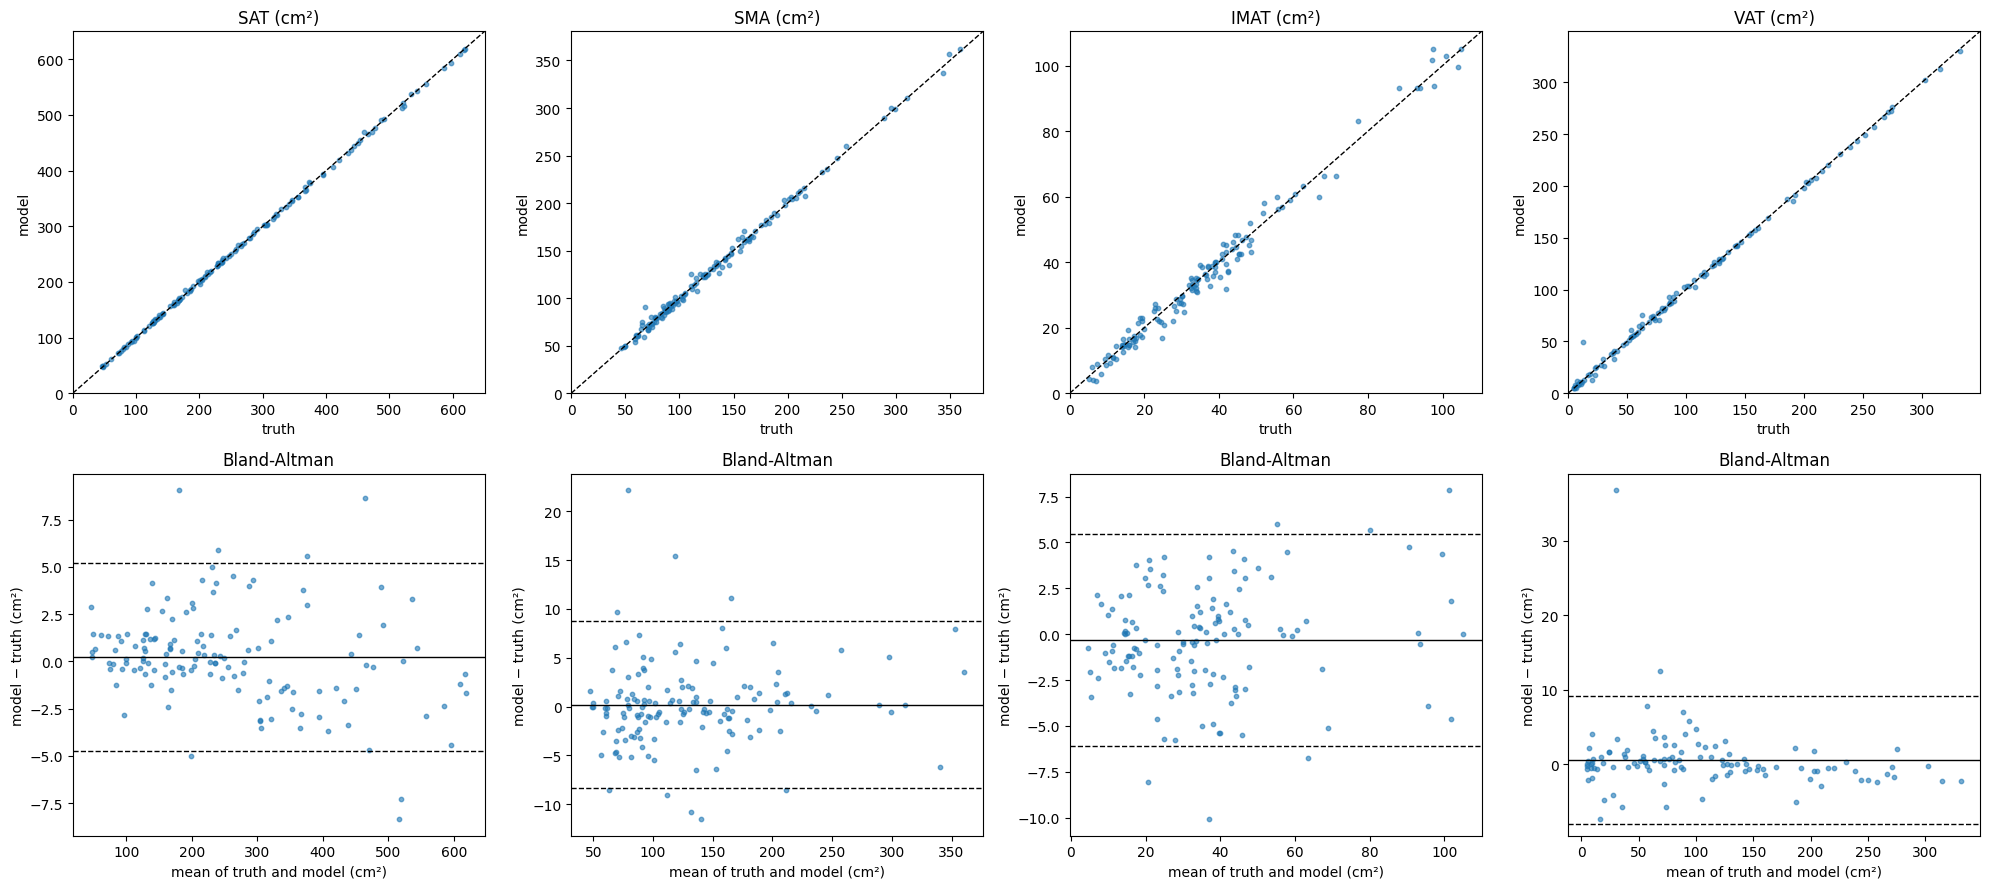

In [7]:
# scatter (model vs truth) and Bland-Altman plots
AREAS = ['SAT_cm2', 'SMA_cm2', 'IMAT_cm2', 'VAT_cm2']
fig, axes = plt.subplots(2, len(AREAS), figsize=(5 * len(AREAS), 9))
for k, metric in enumerate(AREAS):
    t, p = m[f'true_{metric}'], m[f'pred_{metric}']
    keep = t >= MIN_AREA_CM2; t, p = t[keep], p[keep]
    if len(t) < 2:
        axes[0, k].set_title(f'{metric}: too few slices'); axes[1, k].axis('off'); continue
    lim = [0, max(t.max(), p.max()) * 1.05]
    ax = axes[0, k]; ax.scatter(t, p, s=10, alpha=0.6); ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_title(metric.replace('_cm2', ' (cm²)'))
    ax.set_xlabel('truth'); ax.set_ylabel('model')
    mean, diff = (t + p) / 2, p - t
    ax = axes[1, k]; ax.scatter(mean, diff, s=10, alpha=0.6)
    for y, ls in [(diff.mean(), '-'), (diff.mean() + 1.96 * diff.std(), '--'), (diff.mean() - 1.96 * diff.std(), '--')]:
        ax.axhline(y, color='k', ls=ls, lw=1)
    ax.set_xlabel('mean of truth and model (cm²)'); ax.set_ylabel('model − truth (cm²)'); ax.set_title('Bland-Altman')
plt.tight_layout(); fig.savefig(f'{FIGS}/area_agreement.png', dpi=150, bbox_inches='tight'); plt.show()

**The Phase 2 idea in one picture.** Tissue area along the whole scan instead of one L3 number. Only annotated slices (every 5th, 25 mm apart) can be compared with truth; on new scans the model can measure every 5 mm slice.

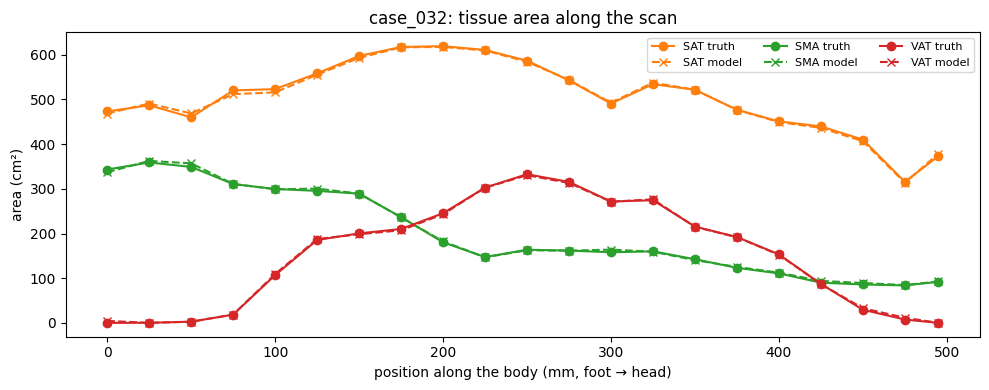

In [8]:
# preview of the multi-slice idea: a craniocaudal profile for one test case
cid = m.groupby('id').size().idxmax()            # the test case with the most measured slices
c = m[m.id == cid].sort_values('z_mm')
fig, ax = plt.subplots(figsize=(10, 4))
for metric, col in [('SAT_cm2', 'tab:orange'), ('SMA_cm2', 'tab:green'), ('VAT_cm2', 'tab:red')]:
    ax.plot(c['z_mm'], c[f'true_{metric}'], 'o-', color=col, label=f'{metric[:-4]} truth')
    ax.plot(c['z_mm'], c[f'pred_{metric}'], 'x--', color=col, label=f'{metric[:-4]} model')
ax.set_xlabel('position along the body (mm, foot → head)'); ax.set_ylabel('area (cm²)')
ax.set_title(f'{cid}: tissue area along the scan'); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); fig.savefig(f'{FIGS}/profile_{cid}.png', dpi=150, bbox_inches='tight'); plt.show()

**Error analysis.** The 4 slices with the largest VAT error. Red = model calls it VAT, truth doesn't; blue = truth VAT the model missed; yellow = agree.

      id  z  z_mm  true_VAT_cm2  pred_VAT_cm2  VAT_err
case_014 75 375.0          12.2          49.0     36.8
case_034 30 150.0          62.8          75.3     12.5
case_047 85 425.0          53.3          61.2      7.8
case_013 55 275.0          20.0          12.6     -7.4


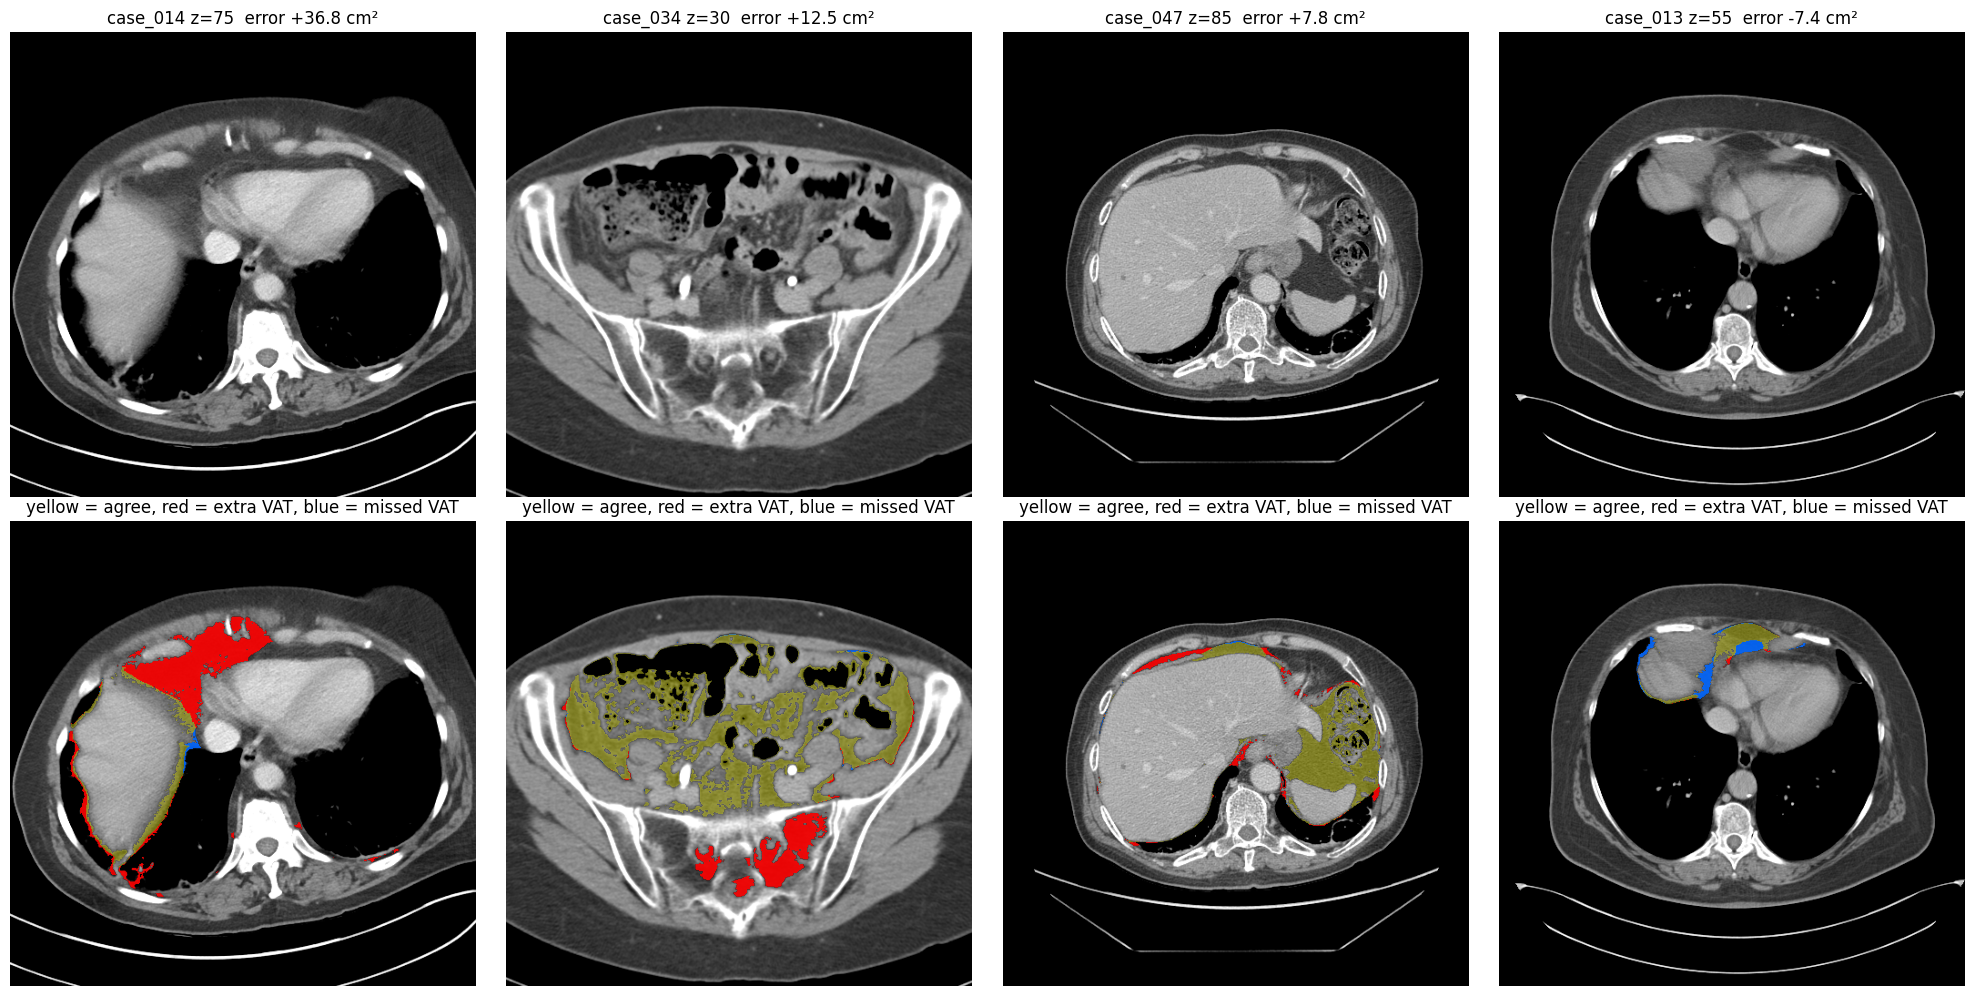

In [9]:
# inspect the worst VAT slices
m['VAT_err'] = m['pred_VAT_cm2'] - m['true_VAT_cm2']
worst = m.reindex(m['VAT_err'].abs().sort_values(ascending=False).index).head(4)
print(worst[['id', 'z', 'z_mm', 'true_VAT_cm2', 'pred_VAT_cm2', 'VAT_err']].round(1).to_string(index=False))

fat_range = lambda hu: (hu >= FAT_HU[0]) & (hu <= FAT_HU[1])
fig, axes = plt.subplots(2, len(worst), figsize=(5 * len(worst), 10), squeeze=False)
for k, (_, r) in enumerate(worst.iterrows()):
    d = np.load(f'{PROC}/{r.id}.npz')
    i = int(np.where(d['z'] == r.z)[0][0])
    hu, truth = d['image'][i], d['label'][i]
    pred = predict(hu[None])[0]
    vat_t, vat_p = (truth == ABD) & fat_range(hu), (pred == ABD) & fat_range(hu)
    show = np.clip(hu, -200, 250)
    axes[0, k].imshow(show, cmap='gray'); axes[0, k].set_title(f'{r.id} z={r.z}  error {r.VAT_err:+.1f} cm²')
    overlay = np.zeros(hu.shape + (4,))
    overlay[vat_t & vat_p] = [1, 1, 0, 0.35]; overlay[vat_p & ~vat_t] = [1, 0, 0, 0.9]; overlay[vat_t & ~vat_p] = [0, 0.4, 1, 0.9]
    axes[1, k].imshow(show, cmap='gray'); axes[1, k].imshow(overlay)
    axes[1, k].set_title('yellow = agree, red = extra VAT, blue = missed VAT')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); fig.savefig(f'{FIGS}/vat_outliers.png', dpi=150, bbox_inches='tight'); plt.show()

**Did the fix work?** Compares this version against v1: area agreement, Dice, and what happens to v1's worst VAT slices. Note: some difference between runs is just training randomness, so look for consistent changes, especially on the diaphragm-level slices.

In [12]:
# v1 vs v2 comparison (did adding the mediastinum class help?)
V1_MODELS = f'{ROOT}/models'
if VERSION != 'v1' and os.path.exists(f'{V1_MODELS}/test_agreement.csv'):
    # 1) area agreement, side by side
    a1 = pd.read_csv(f'{V1_MODELS}/test_agreement.csv').set_index('metric')
    a2 = agree.set_index('metric')
    comp = pd.DataFrame({'bias_v1': a1['bias'], 'bias_v2': a2['bias'],
                         'mape_v1': a1['mean_abs_pct_err'], 'mape_v2': a2['mean_abs_pct_err'],
                         'loa_width_v1': a1['loa_high'] - a1['loa_low'], 'loa_width_v2': a2['loa_high'] - a2['loa_low']}).round(2)
    print('Area agreement on the test set (lower |bias|, MAPE and LoA width = better):')
    print(comp.to_string())
    # 2) segmentation Dice, side by side (shared classes)
    d1 = pd.read_csv(f'{V1_MODELS}/test_dice.csv').set_index('class')['test_dice']
    d2 = pd.read_csv(f'{MODELS}/test_dice.csv').set_index('class')['test_dice']
    print('\nTest Dice:'); print(pd.DataFrame({'v1': d1, 'v2': d2}).round(3).to_string())
    # 3) the slices that were worst in v1: what happens to them in v2?
    m1 = pd.read_csv(f'{V1_MODELS}/test_body_composition.csv')
    m1['VAT_err_v1'] = m1['pred_VAT_cm2'] - m1['true_VAT_cm2']
    worst_v1 = m1.reindex(m1['VAT_err_v1'].abs().sort_values(ascending=False).index).head(8)[['id', 'z', 'z_mm', 'true_VAT_cm2', 'VAT_err_v1']]
    print('\nv1 worst VAT slices, re-measured with v2:')
    print(worst_v1.merge(m[['id', 'z', 'VAT_err']].rename(columns={'VAT_err': 'VAT_err_v2'}), on=['id', 'z']).round(1).to_string(index=False))
else:
    print('No v1 results found to compare against.')

Area agreement on the test set (lower |bias|, MAPE and LoA width = better):
           bias_v1  bias_v2  mape_v1  mape_v2  loa_width_v1  loa_width_v2
metric                                                                   
SAT_cm2       0.30     0.26     0.80     0.84         10.47          9.94
SMA_cm2      -0.59     0.21     2.63     2.71         15.91         17.05
IMAT_cm2     -0.86    -0.33     8.21     8.23         11.49         11.54
VAT_cm2       1.37     0.53     7.44     6.99         18.54         17.15
muscle_HU    -0.02     0.03     1.92     1.89          4.34          4.27
bone_HU      -0.88    -0.35     3.44     3.69         55.75         56.96

Test Dice:
                     v1     v2
class                         
abdominal cavity  0.978  0.977
bone              0.941  0.936
mediastinum         NaN  0.940
muscle            0.948  0.946
subcutaneous      0.980  0.979
thoracic cavity   0.983  0.983

v1 worst VAT slices, re-measured with v2:
      id  z  z_mm  true_VAT_c

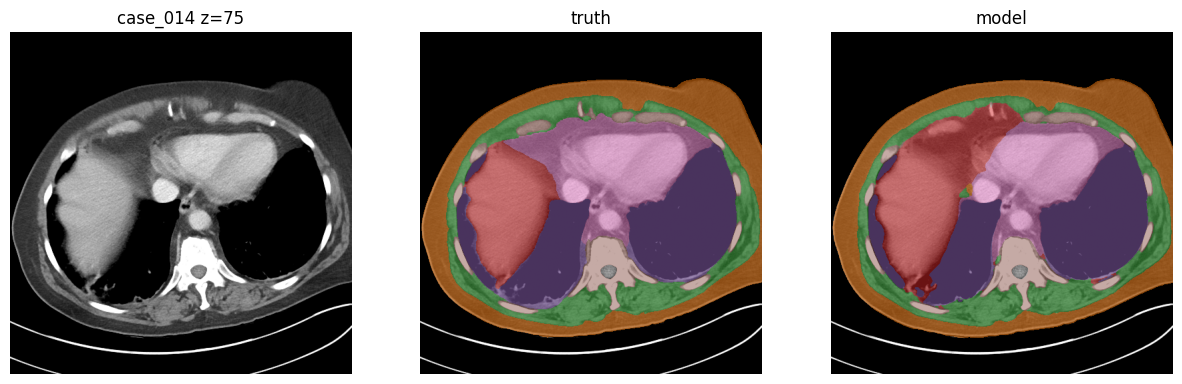

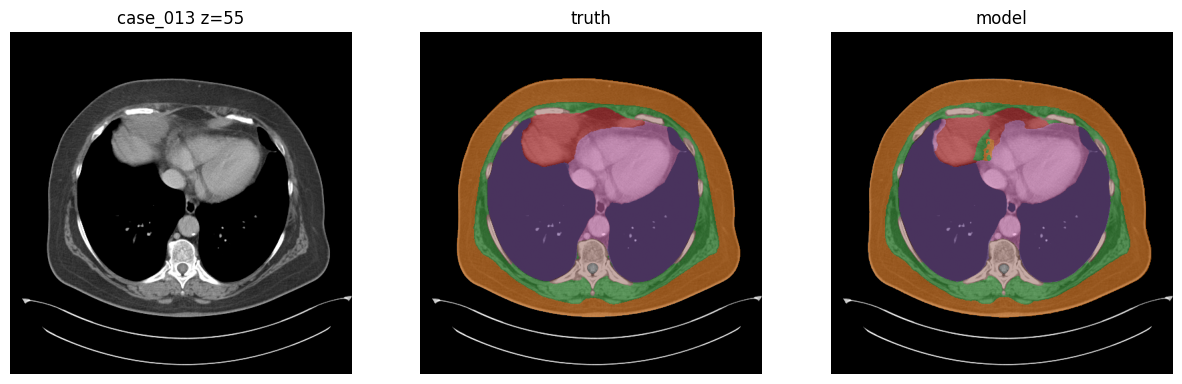

In [13]:
# what do truth and model actually call the cardiophrenic region?
for cid, z in [('case_014', 75), ('case_013', 55)]:
    d = np.load(f'{PROC}/{cid}.npz'); i = int(np.where(d['z'] == z)[0][0])
    hu, truth = d['image'][i], d['label'][i]; pred = predict(hu[None])[0]
    show = np.clip(hu, -200, 250)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(show, cmap='gray'); ax[0].set_title(f'{cid} z={z}')
    for a, lab, t in [(ax[1], truth, 'truth'), (ax[2], pred, 'model')]:
        a.imshow(show, cmap='gray')
        a.imshow(np.ma.masked_where((lab == 0) | (lab == IGNORE), lab), cmap='tab10', vmin=0, vmax=9, alpha=0.5)
        a.set_title(t)
    for a in ax: a.axis('off')
    plt.show()